In [1]:
%pip install torch
%pip install numpy pandas matplotlib seaborn scikit-learn tensorflow pillow
%pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 34.0 MB/s  0:00:14m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 41.2 MB/s  0:00:13m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 42.9 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 23.4 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 14.6 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 15.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 18.3 MB/s  0:00:23m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 22.0 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 17.7 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 14.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 17.3 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import kagglehub
from pathlib import Path

# Download latest version
path = kagglehub.dataset_download("ashfakyeafi/road-vehicle-images-dataset")
DATASET_DIR = Path(path)/"trafic_data"
for split in ["train", "valid"]:
    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"

    print(f"\n{split.upper()}")
    print("Images directory exists:", images_dir.exists())
    print("Labels directory exists:", labels_dir.exists())

100%|██████████| 115M/115M [00:01<00:00, 61.0MB/s] 

Extracting files...



TRAIN
Images directory exists: True
Labels directory exists: True

VALID
Images directory exists: True
Labels directory exists: True


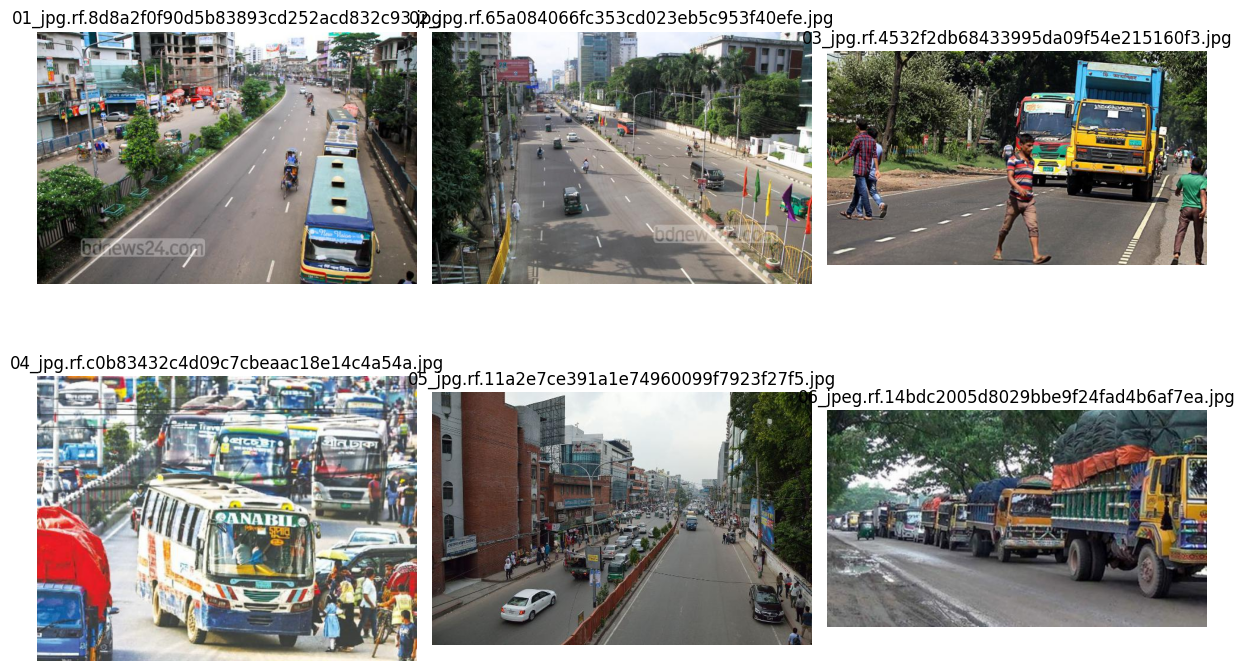

In [3]:

from PIL import Image
import matplotlib.pyplot as plt

images_dir = DATASET_DIR / "train" / "images"
image_files = []

for ext in ["*.jpeg", "*.jpg", "*.png", "*.webp"]:
    image_files.extend(images_dir.glob(ext))

plt.figure(figsize=(12, 8))

for i, image_path in enumerate(image_files[:6]):
    with Image.open(image_path) as img:
        plt.subplot(2, 3, i + 1)
        plt.imshow(img.convert("RGB"))
        plt.title(image_path.name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import yaml

yaml_path = DATASET_DIR / "data_1.yaml"

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)


class_names = data["names"]
num_classes = data["nc"]

class_ids = set(range(num_classes))
print(data)
print("Classes:", data.get("names"))
print("Number of classes:", data.get("nc"))
print("Expected class IDs:", class_ids)


{'train': '../train/images', 'val': '../valid/images', 'nc': 21, 'names': ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']}
Classes: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']
Number of classes: 21
Expected class IDs: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20}


In [5]:

# Get the valid class IDs
if isinstance(class_names, dict):
    valid_class_ids = set(map(int, class_names.keys()))
else:
    valid_class_ids = set(range(len(class_names)))

print("Class names:", class_names)
print("Number of classes:", num_classes)
print("Valid class IDs:", valid_class_ids)

Class names: ['ambulance', 'army vehicle', 'auto rickshaw', 'bicycle', 'bus', 'car', 'garbagevan', 'human hauler', 'minibus', 'minivan', 'motorbike', 'pickup', 'policecar', 'rickshaw', 'scooter', 'suv', 'taxi', 'three wheelers -CNG-', 'truck', 'van', 'wheelbarrow']
Number of classes: 21
Valid class IDs: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20}


In [6]:

def check_annotations(name, valid_class_ids):
    labels_dir = DATASET_DIR / name / "labels"
    images_dir = DATASET_DIR / name / "images"

    valid_images = []
    invalid_images = []
    missing_labels = []
    empty_labels = []

    for ext in ["*.jpeg", "*.jpg", "*.png", "*.webp"]:
        for img_path in images_dir.glob(ext):
            label_path = labels_dir / f"{img_path.stem}.txt"

            # Check if the label file exists
            if not label_path.exists():
                missing_labels.append(img_path)
                continue

            content = label_path.read_text().strip()

            if not content:
                empty_labels.append(img_path)
                continue

            lines = content.splitlines()

            is_valid = True

            for line in lines:
                values = line.split()

                # Each annotation must contain 5 values
                if len(values) != 5:
                    is_valid = False
                    break

                try:
                    class_id = int(values[0])
                    x, y, width, height = map(float, values[1:])
                except ValueError:
                    is_valid = False
                    break

                # Check class ID
                if class_id not in valid_class_ids:
                    is_valid = False
                    break

                # Check normalized coordinates
                if not (0 <= x <= 1 and 0 <= y <= 1
                        and 0 <= width <= 1 and 0 <= height <= 1):
                    is_valid = False
                    break
                
                if (x - width / 2 < 0 or x + width / 2 > 1
                    or y - height / 2 < 0 or y + height / 2 > 1):
                    is_valid = False
                    break

                # Width and height must be positive
                if width == 0 or height == 0:
                    is_valid = False
                    break

            if is_valid:
                valid_images.append(img_path)
            else:
                invalid_images.append(img_path)

   

    return valid_images, invalid_images, missing_labels, empty_labels


In [7]:
train_images = check_annotations("train", valid_class_ids)[0]
valid_images = check_annotations("valid", valid_class_ids)[0]

print(len(train_images))
print(len(valid_images))


2702
298


In [8]:
corrupted_images = []
for image_files in [train_images,valid_images]:
    for img_path in image_files:
        try:
            with Image.open(img_path) as img:
                img.verify()
        except Exception:
            corrupted_images.append(img_path)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [9]:
from sklearn.model_selection import train_test_split

# Séparer les images d'entraînement et de test
train_images, test_images = train_test_split(
    train_images,
    test_size=405,
    random_state=42,
    shuffle=True
)

print("Train :", len(train_images))
print("Validation :", len(valid_images))
print("Test :", len(test_images))

Train : 2297
Validation : 298
Test : 405


In [10]:
print(train_images[0])
print(type(train_images[0]))

/root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/train/images/Navid_130_jpg.rf.b784d8d1b278bac62b6865bb515a275b.jpg
<class 'pathlib.PosixPath'>


In [11]:
import os

# Clone the official repository
!git clone https://github.com/WongKinYiu/yolov9.git

# Move into the repository
os.chdir("yolov9")

# Display current directory
print("Working directory:", os.getcwd())

Cloning into 'yolov9'...
remote: Enumerating objects: 781, done.
remote: Total 781 (delta 0), reused 0 (delta 0), pack-reused 781 (from 1)
Receiving objects: 100% (781/781), 3.27 MiB | 12.00 MiB/s, done.
Resolving deltas: 100% (330/330), done.
Working directory: /yolov9


In [12]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 45.4 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 31.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 27.8 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 25.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 582.8/582.8 kB 22.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 27.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [thop]2m15/16 [thop]vision]ns]eadless]
Note: you may need to restart the kernel to use updated packages.


In [13]:
import requests

weights_url = "https://github.com/WongKinYiu/yolov9/releases/download/v0.1/yolov9-c.pt"
weights_path = "yolov9-c.pt"

response = requests.get(weights_url)
response.raise_for_status()

with open(weights_path, "wb") as f:
    f.write(response.content)

print("Weights downloaded successfully!")

Weights downloaded successfully!


In [14]:
from pathlib import Path

weights_path = Path("yolov9-c.pt")

print("File exists:", weights_path.exists())

if weights_path.exists():
    print("File size:", round(weights_path.stat().st_size / (1024 * 1024), 2), "MB")

File exists: True
File size: 98.37 MB


In [15]:
from pathlib import Path

model_config = Path("models/detect/yolov9-c.yaml")

print("File exists:", model_config.exists())

if model_config.exists():
    print(model_config.read_text()[:2000])

File exists: True
# YOLOv9

# parameters
nc: 80  # number of classes
depth_multiple: 1.0  # model depth multiple
width_multiple: 1.0  # layer channel multiple
#activation: nn.LeakyReLU(0.1)
#activation: nn.ReLU()

# anchors
anchors: 3

# YOLOv9 backbone
backbone:
  [
   [-1, 1, Silence, []],  
   
   # conv down
   [-1, 1, Conv, [64, 3, 2]],  # 1-P1/2

   # conv down
   [-1, 1, Conv, [128, 3, 2]],  # 2-P2/4

   # elan-1 block
   [-1, 1, RepNCSPELAN4, [256, 128, 64, 1]],  # 3

   # avg-conv down
   [-1, 1, ADown, [256]],  # 4-P3/8

   # elan-2 block
   [-1, 1, RepNCSPELAN4, [512, 256, 128, 1]],  # 5

   # avg-conv down
   [-1, 1, ADown, [512]],  # 6-P4/16

   # elan-2 block
   [-1, 1, RepNCSPELAN4, [512, 512, 256, 1]],  # 7

   # avg-conv down
   [-1, 1, ADown, [512]],  # 8-P5/32

   # elan-2 block
   [-1, 1, RepNCSPELAN4, [512, 512, 256, 1]],  # 9
  ]

# YOLOv9 head
head:
  [
   # elan-spp block
   [-1, 1, SPPELAN, [512, 256]],  # 10

   # up-concat merge
   [-1, 1, nn.Upsample, [None,

In [16]:
hyp_path = Path("data/hyps/hyp.scratch-high.yaml")

print("File exists:", hyp_path.exists())

if hyp_path.exists():
    print(hyp_path.read_text()[:2000])

File exists: True
lr0: 0.01  # initial learning rate (SGD=1E-2, Adam=1E-3)
lrf: 0.01  # final OneCycleLR learning rate (lr0 * lrf)
momentum: 0.937  # SGD momentum/Adam beta1
weight_decay: 0.0005  # optimizer weight decay 5e-4
warmup_epochs: 3.0  # warmup epochs (fractions ok)
warmup_momentum: 0.8  # warmup initial momentum
warmup_bias_lr: 0.1  # warmup initial bias lr
box: 7.5  # box loss gain
cls: 0.5  # cls loss gain
cls_pw: 1.0  # cls BCELoss positive_weight
obj: 0.7  # obj loss gain (scale with pixels)
obj_pw: 1.0  # obj BCELoss positive_weight
dfl: 1.5  # dfl loss gain
iou_t: 0.20  # IoU training threshold
anchor_t: 5.0  # anchor-multiple threshold
# anchors: 3  # anchors per output layer (0 to ignore)
fl_gamma: 0.0  # focal loss gamma (efficientDet default gamma=1.5)
hsv_h: 0.015  # image HSV-Hue augmentation (fraction)
hsv_s: 0.7  # image HSV-Saturation augmentation (fraction)
hsv_v: 0.4  # image HSV-Value augmentation (fraction)
degrees: 0.0  # image rotation (+/- deg)
translat

In [17]:
from pathlib import Path

# Check important YOLOv9 files
required_files = [
    "train_dual.py",
    "detect.py",
    "models/detect/yolov9-c.yaml",
    "data/hyps/hyp.scratch-high.yaml",
    "yolov9-c.pt"
]

for file in required_files:
    path = Path(file)
    print(f"{file}: {'Found' if path.exists() else 'Missing'}")

train_dual.py: Found
detect.py: Found
models/detect/yolov9-c.yaml: Found
data/hyps/hyp.scratch-high.yaml: Found
yolov9-c.pt: Found


In [18]:
%pip install setuptools

Note: you may need to restart the kernel to use updated packages.


In [19]:
%pip install setuptools==80.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 11.8 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.0.0
    Uninstalling setuptools-84.0.0:
      Successfully uninstalled setuptools-84.0.0
Note: you may need to restart the kernel to use updated packages.


In [20]:
from pathlib import Path

print(Path.cwd())

/yolov9


In [21]:
from pathlib import Path

# Look for the cloned YOLOv9 repository
possible_paths = [
    Path.cwd() / "yolov9",
    Path.cwd().parent / "yolov9",
    Path.cwd().parent.parent / "yolov9"
]

YOLOV9_DIR = None

for path in possible_paths:
    if (path / "train_dual.py").exists():
        YOLOV9_DIR = path
        break

if YOLOV9_DIR:
    print("YOLOv9 repository found:", YOLOV9_DIR)
else:
    print("Repository not found. Check where you cloned YOLOv9.")

YOLOv9 repository found: /yolov9


In [22]:
import os

os.chdir(YOLOV9_DIR)

print("Current directory:", Path.cwd())
print("Training script exists:", Path("train_dual.py").exists())

Current directory: /yolov9
Training script exists: True


In [23]:
# Make sure the three splits are available
print("Training:", len(train_images))
print("Validation:", len(valid_images))
print("Testing:", len(test_images))

# Save image paths into text files
(DATASET_DIR / "train.txt").write_text(
    "\n".join(str(p.resolve()) for p in train_images)
)

(DATASET_DIR / "valid.txt").write_text(
    "\n".join(str(p.resolve()) for p in valid_images)
)

(DATASET_DIR / "test.txt").write_text(
    "\n".join(str(p.resolve()) for p in test_images)
)

print("Dataset split files created successfully!")

Training: 2297
Validation: 298
Testing: 405
Dataset split files created successfully!


In [24]:
import yaml

roadvision_config = {
    "train": str((DATASET_DIR / "train.txt").resolve()),
    "val": str((DATASET_DIR / "valid.txt").resolve()),
    "test": str((DATASET_DIR / "test.txt").resolve()),
    "nc": num_classes,
    "names": class_names
}

# Create the configuration file inside YOLOv9
config_path = Path("data/roadvision.yaml")
config_path.parent.mkdir(parents=True, exist_ok=True)

with open(config_path, "w") as file:
    yaml.safe_dump(
        roadvision_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )

print("Configuration created:", config_path)
print(config_path.read_text())

Configuration created: data/roadvision.yaml
train: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/train.txt
val: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/valid.txt
test: /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/test.txt
nc: 21
names:
- ambulance
- army vehicle
- auto rickshaw
- bicycle
- bus
- car
- garbagevan
- human hauler
- minibus
- minivan
- motorbike
- pickup
- policecar
- rickshaw
- scooter
- suv
- taxi
- three wheelers -CNG-
- truck
- van
- wheelbarrow



In [27]:
import requests
from pathlib import Path

# Create the configuration directory
font_dir = Path("/root/.config/Ultralytics")
font_dir.mkdir(parents=True, exist_ok=True)

# Download Arial font
url = "https://ultralytics.com/assets/Arial.ttf"

response = requests.get(url, allow_redirects=True, timeout=30)
response.raise_for_status()

font_path = font_dir / "Arial.ttf"
font_path.write_bytes(response.content)

print("Font downloaded:", font_path.exists())
print("File size:", font_path.stat().st_size, "bytes")

Font downloaded: True
File size: 773236 bytes


In [ ]:
from pathlib import Path
import re
import torch

ROOT = Path("/yolov9")

# 1. Fix PyTorch weights_only compatibility
files_to_patch = {
    "train_dual.py": [
        ("torch.load(weights, map_location='cpu')",
         "torch.load(weights, map_location='cpu', weights_only=False)")
    ],
    "models/experimental.py": [
        ("torch.load(attempt_download(w), map_location='cpu')",
         "torch.load(attempt_download(w), map_location='cpu', weights_only=False)")
    ],
    "hubconf.py": [
        ("torch.load(attempt_download(path), map_location=device)",
         "torch.load(attempt_download(path), map_location=device, weights_only=False)")
    ],
    "utils/general.py": [
        ("torch.load(f, map_location=torch.device('cpu'))",
         "torch.load(f, map_location=torch.device('cpu'), weights_only=False)")
    ]
}

for filename, replacements in files_to_patch.items():
    path = ROOT / filename
    content = path.read_text()

    for old, new in replacements:
        if new in content:
            print(f"Already patched: {filename}")
        elif old in content:
            content = content.replace(old, new)
            print(f"Patched: {filename}")
        else:
            print(f"WARNING: Expected code not found in {filename}")

    path.write_text(content)


# 2. Fix Pillow compatibility in plots.py
plots_path = ROOT / "utils/plots.py"
content = plots_path.read_text()

old = "w, h = self.font.getsize(label)"
new = """bbox = self.font.getbbox(label)
            w, h = bbox[2] - bbox[0], bbox[3] - bbox[1]"""

if new.strip() in content:
    print("Already patched: utils/plots.py")
elif old in content:
    content = content.replace(old, new)
    plots_path.write_text(content)
    print("Patched: utils/plots.py")
else:
    print("Pillow compatibility line not found (check plots.py)")


# 3. Check environment
print("\\n--- Environment ---")
print("Python:", __import__("sys").version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 4. Check training files
required = [
    "train_dual.py",
    "val_dual.py",
    "models/detect/yolov9-c.yaml",
    "data/roadvision.yaml",
    "yolov9-c.pt"
]

print("\\n--- Required files ---")
for filename in required:
    print(("OK" if (ROOT / filename).exists() else "MISSING"), filename)

print("\\nSetup completed.")

In [61]:
import torch
import subprocess
import sys
from pathlib import Path

# 1. Verify GPU availability
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available!")

device = "0"

print("Training on:", torch.cuda.get_device_name(0))

# 2. Configure training
command = [
    sys.executable,
    "train_dual.py",

    "--data", str(config_path),
    "--cfg", "models/detect/yolov9-c.yaml",
    "--weights", "yolov9-c.pt",
    "--hyp", "data/hyps/hyp.scratch-high.yaml",

    "--epochs", "10",
    "--batch-size", "4",
    "--img-size", "640",
    "--device", device,
    "--workers", "0",

    "--project", "runs/train",
    "--name", "roadvision",
    "--exist-ok"
]

from pathlib import Path
import subprocess

print("Starting YOLOv9 training...")

result = subprocess.run(
    command,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

# Save the complete output
log_path = Path("/yolov9/training_error.log")
log_path.write_text(result.stdout)

print("Return code:", result.returncode)
print("Complete log saved to:", log_path)

# Display the last 15000 characters
print("\n========== TRAINING OUTPUT ==========\n")
print(result.stdout[-15000:])

Training on: NVIDIA GeForce RTX 3090
Starting YOLOv9 training...
Return code: 0
Complete log saved to: /yolov9/training_error.log

========== TRAINING OUTPUT ==========

    9/9      7.48G      1.534      1.395      1.409         59        640:  96%|█████████▋| 554/575 01:39
        9/9      7.48G      1.535      1.395      1.409         72        640:  96%|█████████▋| 554/575 01:39
        9/9      7.48G      1.535      1.395      1.409         72        640:  97%|█████████▋| 555/575 01:39
        9/9      7.48G      1.535      1.394      1.409         63        640:  97%|█████████▋| 555/575 01:39
        9/9      7.48G      1.535      1.394      1.409         63        640:  97%|█████████▋| 556/575 01:39
        9/9      7.48G      1.535      1.394      1.409         91        640:  97%|█████████▋| 556/575 01:39
        9/9      7.48G      1.535      1.394      1.409         91        640:  97%|█████████▋| 557/575 01:39
        9/9      7.48G      1.534      1.394      1.409         

In [62]:
import os

results_dir = "runs/train/roadvision"

for file in os.listdir(results_dir):
    print(file)

weights
hyp.yaml
opt.yaml
events.out.tfevents.1793556039.305d426e78c8.1494.0
events.out.tfevents.1793556204.305d426e78c8.1620.0
events.out.tfevents.1793556645.305d426e78c8.1683.0
events.out.tfevents.1793556783.305d426e78c8.1716.0
events.out.tfevents.1793556898.305d426e78c8.1749.0
events.out.tfevents.1793557825.305d426e78c8.1827.0
events.out.tfevents.1793558035.305d426e78c8.1863.0
events.out.tfevents.1793558504.305d426e78c8.2007.0
events.out.tfevents.1793558764.305d426e78c8.2079.0
labels_correlogram.jpg
labels.jpg
results.csv
events.out.tfevents.1793560410.305d426e78c8.2292.0
events.out.tfevents.1793562138.305d426e78c8.2512.0
events.out.tfevents.1793563423.305d426e78c8.2620.0
events.out.tfevents.1793564964.305d426e78c8.2788.0
F1_curve.png
R_curve.png
PR_curve.png
P_curve.png
confusion_matrix.png
results.png


In [63]:
import os

weights_dir = "runs/train/roadvision/weights"

for file in os.listdir(weights_dir):
    print(file)

last.pt
best.pt


In [68]:
!/venv/main/bin/python val_dual.py \
    --data data/roadvision.yaml \
    --weights runs/train/roadvision/weights/best.pt \
    --img 640 \
    --batch-size 4 \
    --task test \
    --device 0

/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
val_dual: data=data/roadvision.yaml, weights=['runs/train/roadvision/weights/best.pt'], batch_size=4, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLO 🚀 v0.1-104-g5b1ea9a Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24177MiB)

Fusing layers... 
yolov9-c summary: 604 layers, 50744478 parameters, 0 gradients, 236.9 GFLOPs
test: Scanning /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-
                 Class     Images 

In [69]:
import os

results_dir = "runs/val/exp2"

for file in os.listdir(results_dir):
    print(file)

F1_curve.png
PR_curve.png
R_curve.png
P_curve.png
confusion_matrix.png


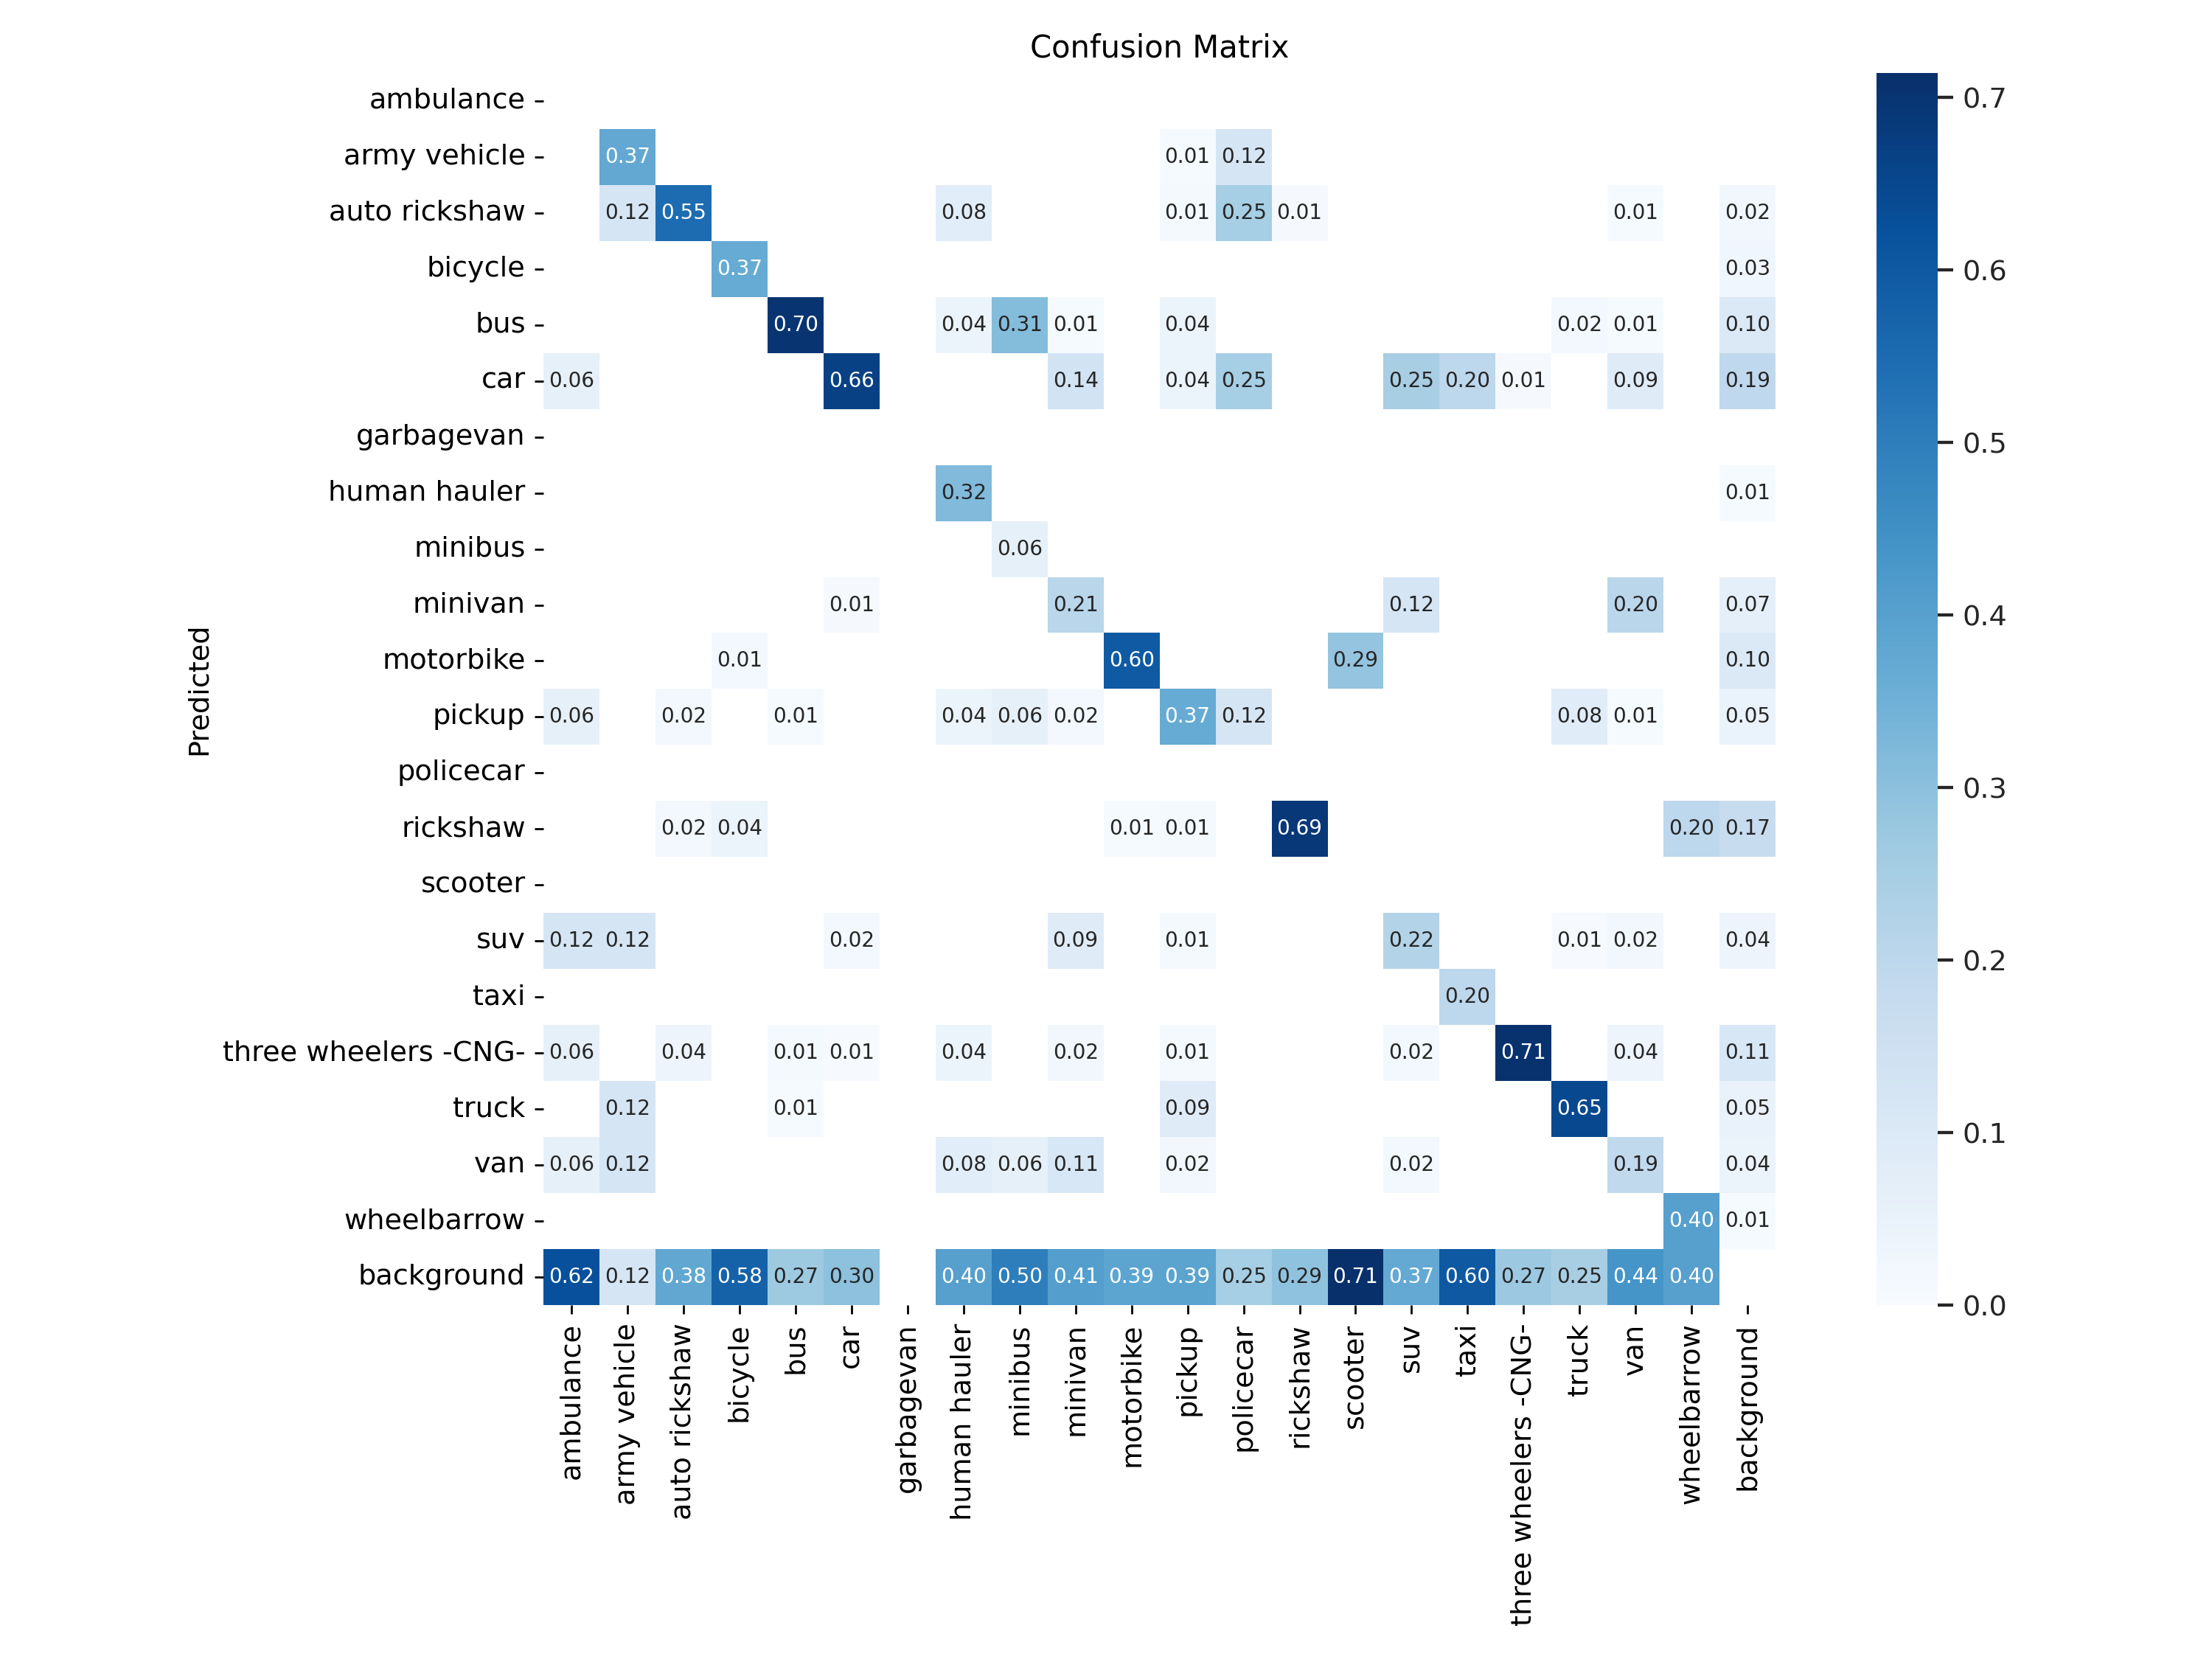

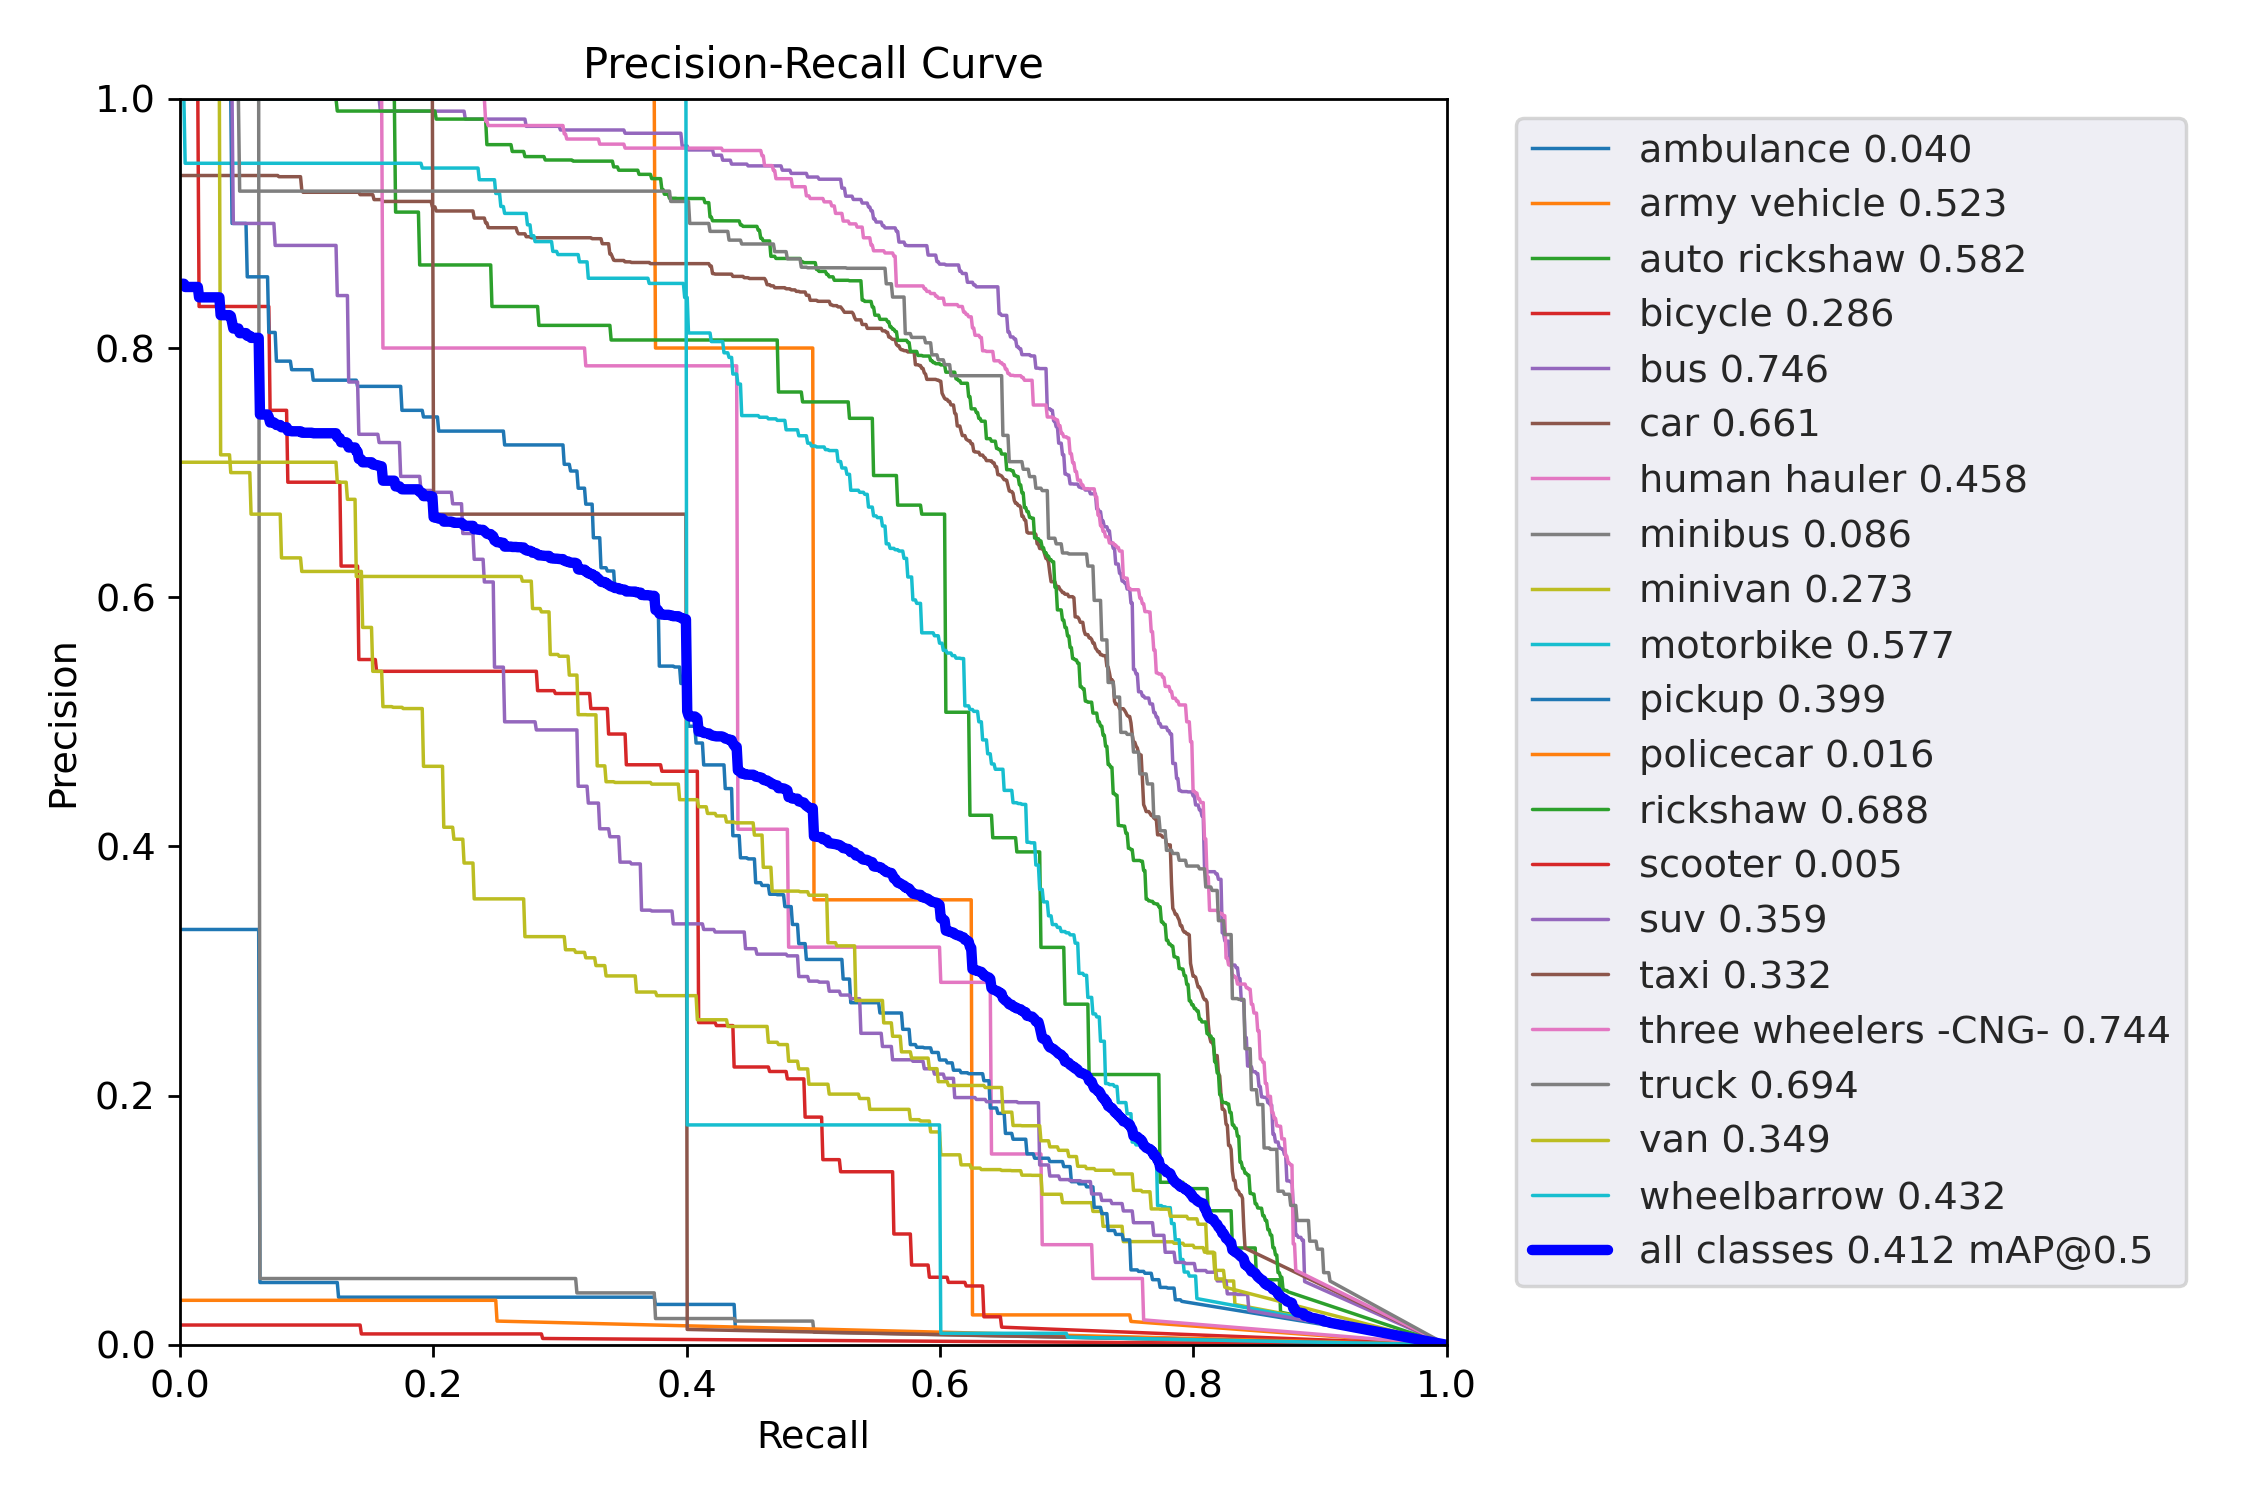

In [70]:
from IPython.display import display, Image

display(Image(filename="runs/val/exp2/confusion_matrix.png"))
display(Image(filename="runs/val/exp2/PR_curve.png"))

In [71]:
import os

weights_dir = "runs/train/roadvision/weights"

for filename in ["best.pt", "last.pt"]:
    path = os.path.join(weights_dir, filename)

    if os.path.exists(path):
        print(f"✓ {filename} exists ({os.path.getsize(path) / (1024**2):.2f} MB)")
    else:
        print(f"✗ {filename} is missing")

✓ best.pt exists (98.08 MB)
✓ last.pt exists (98.08 MB)


In [77]:
import subprocess
import sys
from pathlib import Path

command = [
    sys.executable,
    "val_dual.py",
    "--data", "data/roadvision.yaml",
    "--weights", "runs/train/roadvision/weights/best.pt",
    "--img", "640",
    "--batch-size", "4",
    "--task", "test",
    "--device", "0"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

output = result.stdout + "\n" + result.stderr

# Display evaluation results
print(output)

# Save complete output
output_path = Path("runs/val/roadvision_test_results.txt")
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(output)

if result.returncode != 0:
    raise RuntimeError("Evaluation failed. Check the output above.")

print(f"\nResults saved to: {output_path}")


/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
val_dual: data=data/roadvision.yaml, weights=['runs/train/roadvision/weights/best.pt'], batch_size=4, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLO 🚀 v0.1-104-g5b1ea9a Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24177MiB)

Fusing layers... 
yolov9-c summary: 604 layers, 50744478 parameters, 0 gradients, 236.9 GFLOPs

test: Scanning /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/te

In [ ]:
import os

results_dir = "runs/train/roadvision"

for file in os.listdir(results_dir):
    print(file)

weights
hyp.yaml
opt.yaml
events.out.tfevents.1793556039.305d426e78c8.1494.0
events.out.tfevents.1793556204.305d426e78c8.1620.0
events.out.tfevents.1793556645.305d426e78c8.1683.0
events.out.tfevents.1793556783.305d426e78c8.1716.0
events.out.tfevents.1793556898.305d426e78c8.1749.0
events.out.tfevents.1793557825.305d426e78c8.1827.0
events.out.tfevents.1793558035.305d426e78c8.1863.0
events.out.tfevents.1793558504.305d426e78c8.2007.0
events.out.tfevents.1793558764.305d426e78c8.2079.0
labels_correlogram.jpg
labels.jpg
results.csv
events.out.tfevents.1793560410.305d426e78c8.2292.0
events.out.tfevents.1793562138.305d426e78c8.2512.0
events.out.tfevents.1793563423.305d426e78c8.2620.0
events.out.tfevents.1793564964.305d426e78c8.2788.0
F1_curve.png
R_curve.png
PR_curve.png
P_curve.png
confusion_matrix.png
results.png


In [76]:
from pathlib import Path
import shutil

# Locate the YOLOv9 plotting file
plots_file = Path("utils/plots.py")

# Read its content
content = plots_file.read_text()

old_code = "self.font.getsize(label)"

if old_code in content:
    # Create a backup before modifying
    backup_file = Path("utils/plots.py.bak")
    shutil.copy2(plots_file, backup_file)

    # Replace the deprecated method automatically
    lines = content.splitlines()
    updated_lines = []

    for line in lines:
        if old_code in line:
            indent = line[:len(line) - len(line.lstrip())]
            updated_lines.append(
                indent + "bbox = self.font.getbbox(label)"
            )
            updated_lines.append(
                indent + "w, h = bbox[2] - bbox[0], bbox[3] - bbox[1]"
            )
        else:
            updated_lines.append(line)

    plots_file.write_text("\n".join(updated_lines) + "\n")

    print("Successfully patched utils/plots.py!")
    print(f"Backup created: {backup_file}")

elif "self.font.getbbox(label)" in content:
    print("Already patched! No modification needed.")

else:
    raise RuntimeError("Could not find the expected Pillow code.")

Successfully patched utils/plots.py!
Backup created: utils/plots.py.bak


In [78]:
from pathlib import Path

results_file = Path("runs/val/roadvision_test_results.txt")

content = results_file.read_text(errors="replace")

print(content[-12000:])


/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
val_dual: data=data/roadvision.yaml, weights=['runs/train/roadvision/weights/best.pt'], batch_size=4, imgsz=640, conf_thres=0.001, iou_thres=0.7, max_det=300, task=test, device=0, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False, min_items=0
YOLO 🚀 v0.1-104-g5b1ea9a Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24177MiB)

Fusing layers... 
yolov9-c summary: 604 layers, 50744478 parameters, 0 gradients, 236.9 GFLOPs

test: Scanning /root/.cache/kagglehub/datasets/ashfakyeafi/road-vehicle-images-dataset/versions/2/trafic_data/te

In [92]:
import re
from pathlib import Path

output = Path(
    "runs/val/roadvision_test_results.txt"
).read_text()

# Locate the final metrics table
header = "Class     Images  Instances"
start = output.rfind(header)
end = output.find("Speed:", start)

if start != -1 and end != -1:
    print(output[start:end])
else:
    print("Could not locate the complete metrics table.")
    print(output[-8000:])

Class     Images  Instances          P          R      mAP50   mAP50-95: 100%|██████████| 102/102 00:05
                   all        405       3438      0.567      0.407      0.412      0.266
             ambulance        405         16      0.252     0.0473     0.0398     0.0289
          army vehicle        405          8      0.619        0.5      0.523      0.425
         auto rickshaw        405         53      0.489      0.623      0.582      0.343
               bicycle        405         71      0.456      0.355      0.286       0.17
                   bus        405        444      0.701      0.698      0.746      0.504
                   car        405        784       0.65      0.676      0.661      0.419
          human hauler        405         25      0.626       0.44      0.458      0.256
               minibus        405         16      0.232     0.0625     0.0858     0.0648
               minivan        405        125      0.291      0.344      0.273      0.184
      

In [93]:
! /venv/main/bin/python detect_dual.py \
    --weights runs/train/roadvision/weights/best.pt \
    --source trafic_data/test/images \
    --img 640 \
    --conf-thres 0.25 \
    --iou-thres 0.45 \
    --device 0 \
    --project runs/detect \
    --name roadvision_test \
    --exist-ok

/yolov9/utils/general.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as pkg
detect_dual: weights=['runs/train/roadvision/weights/best.pt'], source=trafic_data/test/images, data=data/coco128.yaml, imgsz=[640, 640], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=0, view_img=False, save_txt=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=roadvision_test, exist_ok=True, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLO 🚀 v0.1-104-g5b1ea9a Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24177MiB)

Fusing layers... 
yolov9-c summary: 604 layers, 50744478 parameters, 0 gradients, 236.9 GFLOP

Dipto_-76_jpg.rf.c51dce82fb0d7a17f26256b5646ad87a.jpg


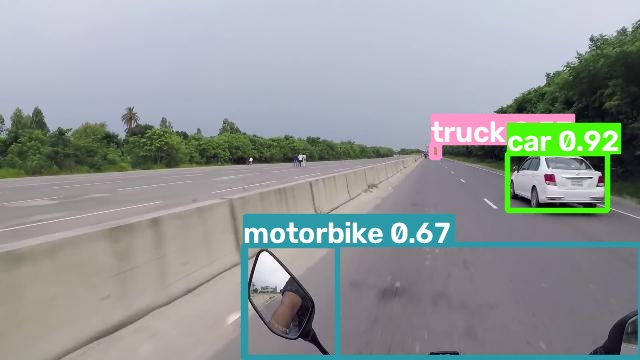

Dipto_650_jpg.rf.536c28247742413aaf476715788ed443.jpg


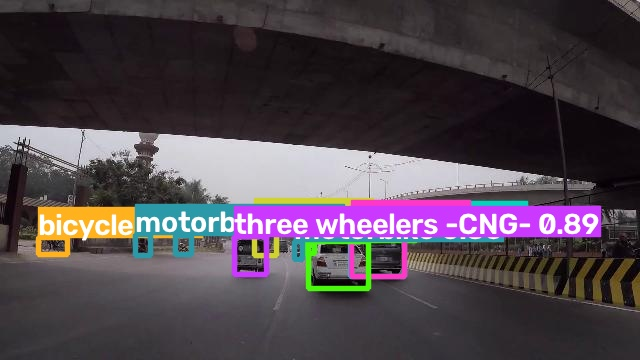

Navid_189_jpg.rf.853aac24f45afe35beeff8e5e77d8467.jpg


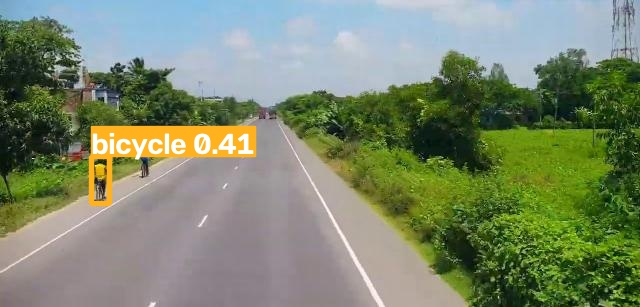

Navid_320_jpg.rf.0675ce694fe9f55cba0a8b7c6272b921.jpg


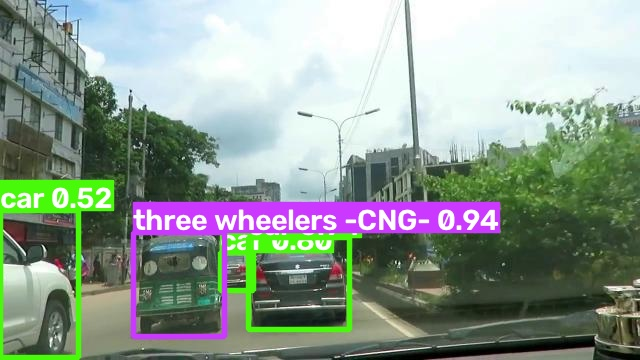

Navid_477_jpg.rf.77b6f5f9d40a4774ca2428078a6f43c5.jpg


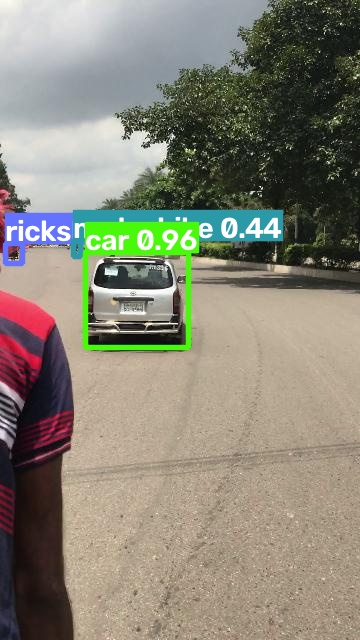

Numan_-404-_jpg.rf.01dce4c4fe2b0002684546967b91712a.jpg


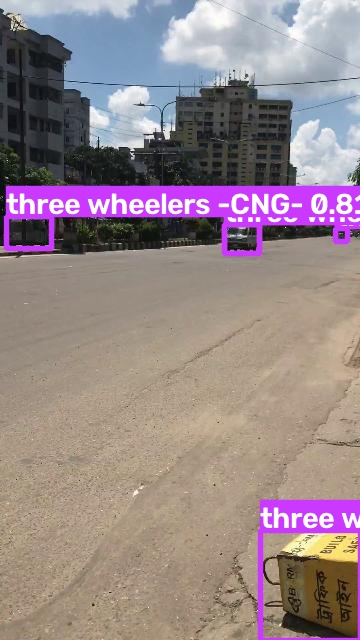

In [94]:
from IPython.display import display, Image as IPImage

for image_path in images[:6]:
    print(image_path.name)
    display(IPImage(filename=str(image_path), width=600))